In [14]:
import numpy as np
import matplotlib as plt
import random
import micrograd
import torch

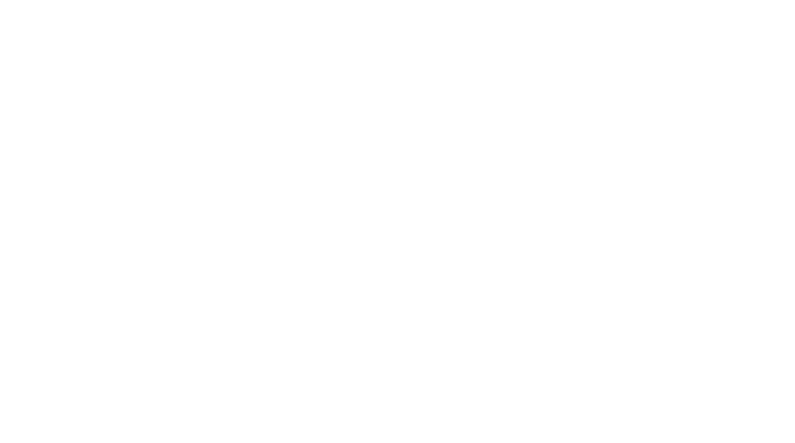

In [15]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the 2-4-1 MLP
torch.manual_seed(7)
model = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

# 2. Run one forward & backward pass
x = torch.tensor([[1.2, -0.8]])
target = torch.tensor([[1.0]])
loss = nn.MSELoss()(model(x), target)
loss.backward()

# 3. Extract layer sizes and gradients
linear_layers = [m for m in model if isinstance(m, nn.Linear)]
layer_sizes = [2, 4, 1]
w_grads = [m.weight.grad.detach().numpy() for m in linear_layers]
b_grads = [m.bias.grad.detach().numpy() for m in linear_layers]

# 4. Set up the plot
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axis("off")

# Compute node coordinates
node_positions = []
for i, size in enumerate(layer_sizes):
    x_pos = i * 3.0
    y_positions = np.linspace(-(size - 1) / 2, (size - 1) / 2, size)
    node_positions.append([(x_pos, y) for y in y_positions])


In [25]:
from micrograd.nn import MLP, Neuron
import math
from micrograd.engine import Value

def tanh(self):
  x = self.data
  t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
  out = Value(t, (self,), "tanh")

  def _backward():
    self.grad += (1 - t**2) * out.grad

  out._backward = _backward
  return out


def exp(self):
  x = self.data
  out = Value(math.exp(x), (self,), "exp")

  def _backward():
    self.grad += out.data * out.grad  # derivative of e^x is e^x

  out._backward = _backward
  return out


def log(self):
  x = self.data
  out = Value(math.log(x), (self,), "log")

  def _backward():
    self.grad += (1 / x) * out.grad  # derivative of ln(x) is 1/x

  out._backward = _backward
  return out

Value.tanh = tanh
Value.exp = exp
Value.log = log

Neuron.__call__ = lambda self, x: (
    lambda act: act.tanh() if self.nonlin else act
)(sum((wi * xi for wi, xi in zip(self.w, x)), self.b))


model = MLP(2, [4, 1])
x = [2.0, -3.0]


def forward():
    out = model(x)
    return (out.exp() + Value(1.0)).log()
    print("Forward output:", out)
    
out = forward()
model.zero_grad()
out.backward()

h = 1e-6
for i, p in enumerate(model.parameters()):
  p.label = f"p{i:02d}"
  orig = p.data

  p.data = orig + h
  f_plus = forward().data

  p.data = orig - h
  f_minus = forward().data

  p.data = orig  # restore original parameter value

  num_grad = (f_plus - f_minus) / (2 * h)
  diff = abs(p.grad - num_grad)
  status = "PASS" if diff < 1e-7 else "FAIL"


for i, p in enumerate(model.parameters()):
  p.label = f"p{i:02d}"
  log_str = f"{p.log().data:+.4f}" if p.data > 0 else "   N/A "
  print(
      f"param {i:02d} | data: {p.data:+.4f} | grad: {p.grad:+.4f} | "
      f"exp: {p.exp().data:+.4f} | tanh: {p.tanh().data:+.4f} | log: {log_str}"
  )


param 00 | data: -0.0292 | grad: +0.0805 | exp: +0.9712 | tanh: -0.0292 | log:    N/A 
param 01 | data: +0.2801 | grad: -0.1208 | exp: +1.3233 | tanh: +0.2730 | log: -1.2725
param 02 | data: +0.0000 | grad: +0.0403 | exp: +1.0000 | tanh: +0.0000 | log:    N/A 
param 03 | data: +0.9188 | grad: +0.0143 | exp: +2.5062 | tanh: +0.7253 | log: -0.0847
param 04 | data: +0.9666 | grad: -0.0215 | exp: +2.6291 | tanh: +0.7472 | log: -0.0339
param 05 | data: +0.0000 | grad: +0.0072 | exp: +1.0000 | tanh: +0.0000 | log:    N/A 
param 06 | data: -0.3339 | grad: -0.0161 | exp: +0.7161 | tanh: -0.3220 | log:    N/A 
param 07 | data: -0.8356 | grad: +0.0242 | exp: +0.4336 | tanh: -0.6835 | log:    N/A 
param 08 | data: +0.0000 | grad: -0.0081 | exp: +1.0000 | tanh: +0.0000 | log:    N/A 
param 09 | data: +0.8152 | grad: +0.0339 | exp: +2.2596 | tanh: +0.6724 | log: -0.2043
param 10 | data: +0.9583 | grad: -0.0508 | exp: +2.6073 | tanh: +0.7435 | log: -0.0426
param 11 | data: +0.0000 | grad: +0.0169 | 